# 03 · Apuração parcial na ordem real do TSE

Parte 18. Pergunta: com x % dos votos válidos já recebidos, na **ordem real em que o TSE recebeu os boletins de urna (BU)**, o modelo `bb_slx` ajustado nos municípios já apurados prevê o resultado final melhor que a contagem bruta e que o swing uniforme? Regras e resultado em [doc 11](../docs/pressupostos/11-apuracao-parcial.md).

Fonte: `data/interim/tse_bweb.parquet` (seção a seção, 2022 e 2026; coletor `src/coleta/tse_bweb.py`). Funções em `src/apuracao.py`. Tabelas em `results/tables/apuracao_*.csv`, figuras em `results/figures/apuracao_*.png`.

**Regra (fixada antes de ver o resultado, não muda).** Cortes de 5, 10, 25, 50, 67 e 90 % dos votos válidos recebidos no Brasil (doméstico), em 2022 e em 2026. O modelo é **útil** se o erro absoluto do Brasil **e** o MAE regional (5 regiões) forem menores que os da (i) contagem bruta e da (ii) swing uniforme em **pelo menos 4 dos 6 cortes, em cada ano**. Alvo: o resultado final real.

**Desenho.**
- Por município, (y_c, n_c) = votos de Lula e válidos das seções recebidas até o corte; n_u = aptos das seções ainda não recebidas × (válidos ÷ aptos do 1º turno do mesmo ano no município).
- Modelo: `bb_slx` (a especificação final, via `Candidato.ajustar`) ajustado em (y_c, n_c) dos municípios com n_c > 0; prevê π̂ do restante. 2026 usa `MAPA_2026_PRE`; 2022 usa `MAPA_FIT_2022` (covariáveis anteriores a 2022). Padronização só nas linhas de treino. Total = Σ y_c + Σ π̂·n_u, por região e Brasil.
- (i) contagem bruta: share já apurado. (ii) swing uniforme: swing nacional médio dos apurados contra o 2º turno anterior (2018 para 2022; 2022 para 2026), somado ao share anterior de cada município não apurado.
- Boa Esperança do Norte (MT, código TSE 73709) não está no parquet do modelo: seus votos apurados entram nos três métodos e no alvo; o restante usa o share do método na UF.
- Intervalos de 95 %: `simular_votos_grupo` (β ~ N(β̂, Σ Conley 200 km), choque de UF com σ_UF, beta-binomial) sobre o restante, somado ao já apurado. σ_UF = 0,0564 (Parte 16 do notebook 02-MLG) e corte de Conley de 200 km (Parte 15) nos dois anos.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")
warnings.filterwarnings("always", message="Covariância não PSD")
from statsmodels.tools.sm_exceptions import PerfectSeparationError
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import especificacoes as E, espacial as S, backtest as BT, apuracao as A, graficos as G, pressupostos as PR, dados as D, saidas as SA
from src.especificacoes import Candidato, Termos
TAB, FIG = ROOT / "results/tables", ROOT / "results/figures"
for p in (TAB, FIG): p.mkdir(parents=True, exist_ok=True)
SEMENTE, B = 7, 1000   # corte e σ_UF vêm de results/tables (Partes 15 e 16 do notebook 02-MLG)
ANOS = (2022, 2026)
BD = D.carregar_base(ROOT)   # municípios, geometria na mesma ordem e pesos Queen (compartilhado com o notebook 02-MLG)
dfm, W = BD.df, BD.W
G.configurar(dfm, FIG)
lat, lon = dfm["lat"].to_numpy(float), dfm["lon"].to_numpy(float)
cd_modelo = dfm["id_municipio_tse"].astype("int64")
dec = json.loads((TAB / "final_decisao.json").read_text())
tf = dec["termos_final"]
CORTE_KM = float(dec["corte_final"])
SIGMA_UF = float(pd.read_csv(TAB / "final_cobertura.csv").query("covariancia == 'conley' and sigma == 'sigma_uf'").valor_sigma.iloc[0])
assert dec["modelo_final"] == "bb_slx"
CF = Candidato("bb_slx", "betabin", "logit", Termos(vars=tuple(v for v in tf["vars"] if not v.startswith("w_")),
                                                      slx=tuple(tf["slx"]), disp=tf["disp"],
                                                      regiao_fundir=tuple(tuple(g) for g in tf["regiao_fundir"])))
secoes = pd.read_parquet(ROOT / "data/interim/tse_bweb.parquet")


## Taxa de válidos do 1º turno como estimador de n_u

`n_u` precisa de uma taxa válidos ÷ aptos anterior ao 2º turno. A leitura literal (só Lula + adversário no 1º turno) ignora o voto de quem escolheu um terceiro candidato no 1º turno e vota nos dois no 2º; a alternativa é o total de válidos do 1º turno. A tabela compara as duas contra o n real do 2º turno (informação só para escolher o estimador, não entra nos métodos).

In [2]:
L = []
for ano in ANOS:
    aptos1 = dfm[f"aptos_1t_{ano}"].astype(float)
    real_r = dfm[f"n_2t_{ano}"] / aptos1
    for nome, num in (("dois_candidatos_1t", dfm[f"votos_pt_1t_{ano}"] + dfm[f"votos_bolsonaro_1t_{ano}"]),
                      ("todos_validos_1t", dfm[f"validos_1t_{ano}"])):
        r = num.astype(float) / aptos1
        L.append({"ano": ano, "taxa": nome, "soma_estimada_sobre_real": float((r * aptos1).sum() / (real_r * aptos1).sum()),
                  "mape_municipal_pct": float((abs(r - real_r) / real_r).mean() * 100)})
TAXAS = pd.DataFrame(L); TAXAS.to_csv(TAB / "apuracao_taxa_nu.csv", index=False)
display(SA.tabela(TAXAS.assign(ano=TAXAS["ano"].astype(str)), "Taxa de válidos do 1º turno como estimador de n_u, contra o n real do 2º turno", numero="1", casas=3,
                  indice=False, rotulos={"ano": "Ano", "taxa": "Taxa", "soma_estimada_sobre_real": "Soma estimada / real", "mape_municipal_pct": "Erro médio por município (%)"},
                  casas_por_coluna={"mape_municipal_pct": 1}))

Ano,Taxa,Soma estimada / real,Erro médio por município (%)
2022,dois_candidatos_1t,"0,914","6,6"
2022,todos_validos_1t,"0,997","2,1"
2026,dois_candidatos_1t,"0,887","9,5"
2026,todos_validos_1t,"0,962","4,1"


## Ordem real e cortes

Os cortes seguem a curva acumulada por instante de recebimento do BU (horário de Brasília). A virada de 2022 (Lula passa de Bolsonaro) está validada no coletor em 18:44 a 68,1 % recebido. O % efetivo de cada corte é um pouco maior que o nominal, porque seções do mesmo instante entram juntas.

In [3]:
L = []
for ano in ANOS:
    s = secoes[secoes.ano == ano]
    for pct in A.CORTES:
        rec = A.recebidas_ate(s, pct)
        L.append({"ano": ano, "corte": pct, "instante": A.instante_do_corte(s, pct).strftime("%d/%m %H:%M"), "pct_efetivo": A.pct_efetivo(s, rec)})
CORTES = pd.DataFrame(L)
tab_cortes = CORTES.pivot(index="corte", columns="ano", values=["instante", "pct_efetivo"])
tab_cortes.columns = [f"{'Instante do BU' if a == 'instante' else '% efetivo'} {b}" for a, b in tab_cortes.columns]
tab_cortes = tab_cortes[[f"{k} {a}" for a in ANOS for k in ("Instante do BU", "% efetivo")]]
tab_cortes = tab_cortes.apply(lambda c: c.astype(float) if c.name.startswith("%") else c)
display(SA.tabela(tab_cortes.rename_axis("Corte (%)"), "Cortes de apuração: instante do boletim (Brasília) e % efetivo dos válidos", numero="2", casas=1))

,Instante do BU 2022,% efetivo 2022,Instante do BU 2026,% efetivo 2026
Corte (%),,,,
5,30/10 17:25,"5,0",25/10 19:28,"5,0"
10,30/10 17:33,"10,0",25/10 19:38,"10,0"
25,30/10 17:55,"25,0",25/10 20:02,"25,0"
50,30/10 18:26,"50,0",25/10 20:26,"50,0"
67,30/10 18:42,"67,0",25/10 20:41,"67,0"
90,30/10 19:08,"90,0",25/10 21:01,"90,0"


## Ajuste, estimativas e intervalos por corte

Os intervalos saem duas vezes: com n_u fixo e com n_u simulado (regra do [doc 11](../docs/pressupostos/11-apuracao-parcial.md), seção 3). Os 6 cortes são aninhados no tempo e as 6 unidades (5 regiões e Brasil) são correlacionadas: a tabela de cortes cobertos por unidade e ano é descritiva, não um teste de calibração, e não se soma entre unidades.

In [4]:
LIN, LIN_REG, LIN_IC, LIN_ICN, LIN_SD, LIN_REP, LIN_NU, FALHAS = [], [], [], [], [], [], [], []
PI_CORTE = {}
# covariáveis defasadas (SLX) de cada ano, construídas uma vez e reusadas pela sensibilidade a n_u
SLX = {ano: S.adicionar_slx(dfm, E.MAPA_2026 if ano == 2026 else BT.MAPA_FIT_2022, list(tf["slx"]), W) for ano in ANOS}
for ano in ANOS:
    s = secoes[secoes.ano == ano].reset_index(drop=True)
    df2, mapa = SLX[ano]
    prois = {k: v for k, v in mapa.items() if k in CF.termos.vars and f"2t_{ano}" in v}
    assert not prois, prois   # nenhuma covariável do modelo vem do 2º turno do próprio ano
    for pct in A.CORTES:
        rec = A.recebidas_ate(s, pct)
        base = A.montar_base(s, dfm, ano, rec)
        real = A.alvo(base)
        info = {"ano": ano, "corte": pct, "pct_efetivo": A.pct_efetivo(s, rec)}
        ests = {"bruta": A.estimativa_bruta(base), "swing": A.estimativa_swing(base)}
        LIN_NU.append({**info, "n_u_estimado": float(base.n_u.sum()), "restante_real": float((base.n_final - base.n_c).sum()),
                       "razao": float(base.n_u.sum() / (base.n_final - base.n_c).sum())})
        pi = None
        try:
            bm = base.reindex(cd_modelo)
            pm = A.ajustar_parcial(CF, df2, mapa, bm.y_c.to_numpy(), bm.n_c.to_numpy(), bm.n_u.to_numpy(), lat, lon, CORTE_KM)
            pi = pd.Series(pm.pi, index=bm.index)
            ests["modelo"] = A.estimativa_modelo(base, pi)
            ic = A.intervalos(pm, bm, base, A.share_uf_modelo(base, pi), CF.ligacao, SIGMA_UF, B, SEMENTE)
            ic = ic.assign(real=real.reindex(ic.index), estimativa=ests["modelo"].reindex(ic.index))
            ic["dentro"] = (ic.real >= ic.q025) & (ic.real <= ic.q975)
            for r_, x in ic.iterrows():
                LIN_IC.append({**info, "regiao": r_, "estimativa_pct": 100 * x.estimativa, "q025_pct": 100 * x.q025, "q975_pct": 100 * x.q975,
                               "real_pct": 100 * x.real, "largura_pp": 100 * (x.q975 - x.q025), "dentro_ic95": bool(x.dentro)})
            fk = A.fatores_nu(base, B, SEMENTE)   # n_u simulado: mesma semente e B, só seções já recebidas
            icn = A.intervalos(pm, bm, base, A.share_uf_modelo(base, pi), CF.ligacao, SIGMA_UF, B, SEMENTE, fatores=fk)
            icn = icn.assign(real=real.reindex(icn.index))
            for r_, x in icn.iterrows():
                LIN_ICN.append({**info, "regiao": r_, "q025_pct": 100 * x.q025, "q975_pct": 100 * x.q975, "real_pct": 100 * x.real,
                                "largura_pp": 100 * (x.q975 - x.q025), "dentro_ic95": bool(x.real >= x.q025 and x.real <= x.q975)})
            LIN_SD.append({**info, "sd_uf_nu": A.sd_uf_nu(base)})
        except np.linalg.LinAlgError as e:   # matriz singular no ajuste conta como derrota do modelo; qualquer outro erro é bug e interrompe
            FALHAS.append({**info, "erro": repr(e)[:200]})
        PI_CORTE[(ano, pct)] = pi
        for met, est in ests.items():
            eb, mr = A.erros(est, real)
            LIN.append({**info, "metodo": met, "estimativa_brasil_pct": 100 * est["Brasil"], "real_brasil_pct": 100 * real["Brasil"],
                        "erro_brasil_com_sinal_pp": 100 * (est["Brasil"] - real["Brasil"]), "erro_brasil_pp": eb, "mae_regional_pp": mr})
            for r_ in real.index.drop("Brasil"):
                LIN_REG.append({**info, "metodo": met, "regiao": r_, "estimativa_pct": 100 * est[r_], "real_pct": 100 * real[r_], "erro_pp": 100 * (est[r_] - real[r_])})
        rep = A.representatividade(base, pi)
        for _, x in rep.iterrows(): LIN_REP.append({**info, **x.to_dict()})
TAB_ERROS = pd.DataFrame(LIN)

In [5]:
METODOS = A.METODOS
IC = pd.DataFrame(LIN_IC)
ICN = pd.DataFrame(LIN_ICN); ICN.to_csv(TAB / "apuracao_ic_nu_simulado.csv", index=False)
pd.DataFrame(LIN_SD).to_csv(TAB / "apuracao_sd_uf_nu.csv", index=False)
# n_u fixo (IC antigo) contra n_u simulado: cortes cobertos de 6, por unidade (5 regiões + Brasil) e ano
CHAVE = ["ano", "corte", "regiao"]
J = IC[CHAVE + ["dentro_ic95", "largura_pp"]].merge(ICN[CHAVE + ["dentro_ic95", "largura_pp"]], on=CHAVE, suffixes=("_fixo", "_sim"))
J["delta_largura_pp"] = J.largura_pp_sim - J.largura_pp_fixo
COB_UNI = J.groupby(["regiao", "ano"]).agg(cortes=("corte", "size"), cobertos_n_u_fixo=("dentro_ic95_fixo", "sum"), cobertos_n_u_simulado=("dentro_ic95_sim", "sum"),
                                         mediana_delta_largura_pp=("delta_largura_pp", "median")).reset_index().rename(columns={"regiao": "unidade"})
COB_UNI.to_csv(TAB / "apuracao_cobertura_unidade.csv", index=False)
COBERTURA = IC.groupby(["ano", "corte"]).agg(dentro=("dentro_ic95", "sum"), total=("dentro_ic95", "size"), largura_brasil_pp=("largura_pp", "last")).reset_index()
COBERTURA["cobertura"] = COBERTURA.dentro / COBERTURA.total
cob = COBERTURA.set_index(["ano", "corte"])["cobertura"]
TAB_ERROS["cobertura_ic95"] = [cob.get((a, c), np.nan) if m == "modelo" else np.nan for a, c, m in zip(TAB_ERROS.ano, TAB_ERROS.corte, TAB_ERROS.metodo)]
for ano in ANOS:
    TAB_ERROS[TAB_ERROS.ano == ano].to_csv(TAB / f"apuracao_{ano}.csv", index=False)
pd.DataFrame(LIN_REG).to_csv(TAB / "apuracao_regioes.csv", index=False)
IC.to_csv(TAB / "apuracao_ic.csv", index=False)
REP = pd.DataFrame(LIN_REP); REP.to_csv(TAB / "apuracao_representatividade.csv", index=False)
NU = pd.DataFrame(LIN_NU); NU.to_csv(TAB / "apuracao_n_restante.csv", index=False)
if FALHAS:
    display(SA.tabela(pd.DataFrame(FALHAS), "Ajustes que falharam (contam como derrota do modelo)", numero="F", indice=False))
RT = {"bruta": "bruta", "swing": "swing", "modelo": "modelo"}
for k, ano in enumerate(ANOS):
    t = TAB_ERROS[TAB_ERROS.ano == ano]
    ex = t.pivot(index="corte", columns="metodo", values=["erro_brasil_pp", "mae_regional_pp"])[[(c, m) for c in ("erro_brasil_pp", "mae_regional_pp") for m in METODOS]]
    ex.columns = [("Erro Brasil " if c == "erro_brasil_pp" else "MAE regional ") + m for c, m in ex.columns]
    display(SA.tabela(ex.rename_axis("Corte (%)"), f"{ano}: erro absoluto do Brasil e MAE regional por corte e método (p.p.)", numero=f"{3 + k}", casas=2))
display(SA.tabela(COB_UNI.assign(ano=COB_UNI["ano"].astype(str)), "Cortes cobertos pelo IC 95% (de 6), por unidade e ano: n_u fixo contra n_u simulado", numero="5", casas=3,
                  indice=False, inteiros=["cortes", "cobertos_n_u_fixo", "cobertos_n_u_simulado"],
                  rotulos={"unidade": "Unidade", "ano": "Ano", "cortes": "Cortes", "cobertos_n_u_fixo": "Cobertos (n_u fixo)", "cobertos_n_u_simulado": "Cobertos (n_u simulado)",
                           "mediana_delta_largura_pp": "Mediana da variação de largura (p.p.)"}))


,Erro Brasil bruta,Erro Brasil swing,Erro Brasil modelo,MAE regional bruta,MAE regional swing,MAE regional modelo
Corte (%),,,,,,
5,"4,57","0,60","0,44","0,77","3,45","0,99"
10,"3,05","1,53","0,80","0,52","3,43","0,85"
25,"2,20","1,62","0,67","0,74","2,88","0,55"
50,"1,23","1,09","0,51","0,66","1,81","0,41"
67,"0,93","0,61","0,32","0,60","1,16","0,25"
90,"0,38","0,13","0,09","0,31","0,34","0,08"


,Erro Brasil bruta,Erro Brasil swing,Erro Brasil modelo,MAE regional bruta,MAE regional swing,MAE regional modelo
Corte (%),,,,,,
5,"0,97","1,19","0,93","1,78","1,49","1,62"
10,"1,48","0,53","0,06","1,04","1,00","0,91"
25,"2,37","0,39","0,25","0,83","0,46","0,25"
50,"1,67","0,53","0,17","0,60","0,33","0,16"
67,"0,95","0,40","0,08","0,49","0,22","0,08"
90,"0,22","0,14","0,02","0,15","0,07","0,03"


Unidade,Ano,Cortes,Cobertos (n_u fixo),Cobertos (n_u simulado),Mediana da variação de largura (p.p.)
Brasil,2022,6,6,6,"0,023"
Brasil,2026,6,6,6,"0,022"
Centro-Oeste,2022,6,6,6,"-0,023"
Centro-Oeste,2026,6,5,5,"-0,036"
Nordeste,2022,6,3,3,"0,025"
Nordeste,2026,6,5,5,"0,022"
Norte,2022,6,4,4,"0,012"
Norte,2026,6,3,3,"0,049"
Sudeste,2022,6,6,6,"-0,030"
Sudeste,2026,6,6,6,"-0,045"


## A regra aplicada

In [6]:
REGRA = A.aplicar_regra(TAB_ERROS)
det = []
for (ano, c), p in TAB_ERROS.groupby(["ano", "corte"]):
    p = p.set_index("metodo")
    if "modelo" not in p.index:
        det.append({"ano": ano, "corte": c, "vence_brasil": False, "vence_regional": False, "vence": False}); continue
    vb = bool((p.loc["modelo", "erro_brasil_pp"] < p.drop(index="modelo")["erro_brasil_pp"]).all())
    vr = bool((p.loc["modelo", "mae_regional_pp"] < p.drop(index="modelo")["mae_regional_pp"]).all())
    det.append({"ano": ano, "corte": c, "vence_brasil": vb, "vence_regional": vr, "vence": vb and vr})
DET = pd.DataFrame(det)
REGRA["veredito"] = np.where(REGRA.util, "modelo útil", "modelo não útil")
DET.to_csv(TAB / "apuracao_regra_cortes.csv", index=False); REGRA.to_csv(TAB / "apuracao_regra.csv", index=False)
det_x = DET.assign(**{c: DET[c].map({True: "sim", False: "não"}) for c in ("vence_brasil", "vence_regional", "vence")}).assign(ano=DET["ano"].astype(str), corte=DET["corte"].astype(str))
display(SA.tabela(det_x, "O modelo vence a contagem bruta e o swing? (menor erro do Brasil e menor MAE regional)", numero="6", indice=False,
                  rotulos={"ano": "Ano", "corte": "Corte (%)", "vence_brasil": "Vence no Brasil", "vence_regional": "Vence na região", "vence": "Vence nos dois"}))
display(SA.tabela(REGRA.drop(columns="util").assign(ano=REGRA["ano"].astype(str)), "Regra fixada de antemão: vitórias do modelo por ano (mínimo de 4 de 6)", numero="7", indice=False,
                  inteiros=["cortes", "vitorias_modelo", "minimo"], rotulos={"ano": "Ano", "cortes": "Cortes", "vitorias_modelo": "Vitórias do modelo", "minimo": "Mínimo", "veredito": "Veredito"}))


Ano,Corte (%),Vence no Brasil,Vence na região,Vence nos dois
2022,5,sim,não,não
2022,10,sim,não,não
2022,25,sim,sim,sim
2022,50,sim,sim,sim
2022,67,sim,sim,sim
2022,90,sim,sim,sim
2026,5,sim,não,não
2026,10,sim,sim,sim
2026,25,sim,sim,sim
2026,50,sim,sim,sim


Ano,Cortes,Vitórias do modelo,Mínimo,Veredito
2022,6,4,4,modelo útil
2026,6,5,4,modelo útil


In [7]:
# Sensibilidade a n_u: mesma regra, com cada definição da taxa. A adotada vem dos ajustes do laço principal; só as outras são refeitas
ADOTADA = (TAB_ERROS.merge(NU[["ano", "corte", "razao"]], on=["ano", "corte"]).rename(columns={"razao": "n_u_sobre_restante_real"})
           .assign(definicao=A.DEFINICAO_TAXA)[["definicao", "ano", "corte", "metodo", "erro_brasil_pp", "mae_regional_pp", "n_u_sobre_restante_real"]])
LS, FALHAS_S = [], []
for definicao in A.DEFINICOES_TAXA:
    if definicao == A.DEFINICAO_TAXA:
        LS.extend(ADOTADA.to_dict("records"))
        continue
    for ano in ANOS:
        s = secoes[secoes.ano == ano].reset_index(drop=True)
        df2, mapa = SLX[ano]
        for pct in A.CORTES:
            rec = A.recebidas_ate(s, pct)
            base = A.montar_base(s, dfm, ano, rec, definicao)
            real = A.alvo(base)
            ests = {"bruta": A.estimativa_bruta(base), "swing": A.estimativa_swing(base)}
            try:
                bm = base.reindex(cd_modelo)
                pm = A.ajustar_parcial(CF, df2, mapa, bm.y_c.to_numpy(), bm.n_c.to_numpy(), bm.n_u.to_numpy(), lat, lon, CORTE_KM)
                ests["modelo"] = A.estimativa_modelo(base, pd.Series(pm.pi, index=bm.index))
            except (np.linalg.LinAlgError, PerfectSeparationError, ValueError, FloatingPointError) as e:
                FALHAS_S.append({"definicao": definicao, "ano": ano, "corte": pct, "erro": repr(e)[:120]})
            restante = float((base.n_final - base.n_c).sum())
            for met, est in ests.items():
                eb, mr = A.erros(est, real)
                LS.append({"definicao": definicao, "ano": ano, "corte": pct, "metodo": met, "erro_brasil_pp": eb, "mae_regional_pp": mr,
                           "n_u_sobre_restante_real": float(base.n_u.sum()) / restante})
SENS = pd.DataFrame(LS)
REGRA_S = pd.concat([A.aplicar_regra(g).assign(definicao=d) for d, g in SENS.groupby("definicao")], ignore_index=True)
REGRA_S["veredito"] = np.where(REGRA_S.util, "modelo útil", "modelo não útil")
SENS.to_csv(TAB / "apuracao_sensibilidade_nu.csv", index=False)
if FALHAS_S:
    display(SA.tabela(pd.DataFrame(FALHAS_S), "Ajustes da sensibilidade que falharam", numero="F2", indice=False))
nu_razao = NU.pivot(index="corte", columns="ano", values="razao").rename_axis("Corte (%)")
nu_razao.columns = [f"n_u / restante real {a}" for a in nu_razao.columns]
display(SA.tabela(nu_razao, "n_u estimado sobre o restante real, por corte (taxa de todos os válidos)", numero="8", casas=3))


,n_u / restante real 2022,n_u / restante real 2026
Corte (%),,
5,"0,997","0,961"
10,"0,997","0,960"
25,"0,997","0,958"
50,"0,996","0,956"
67,"0,996","0,955"
90,"0,995","0,952"


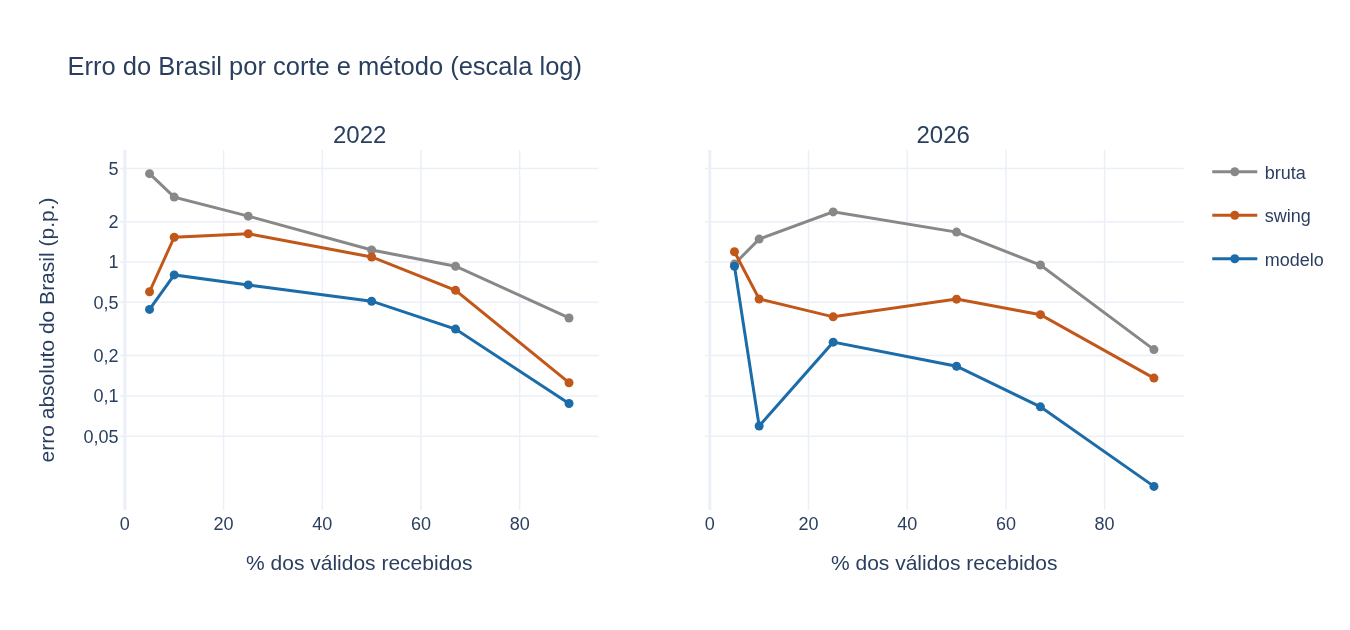

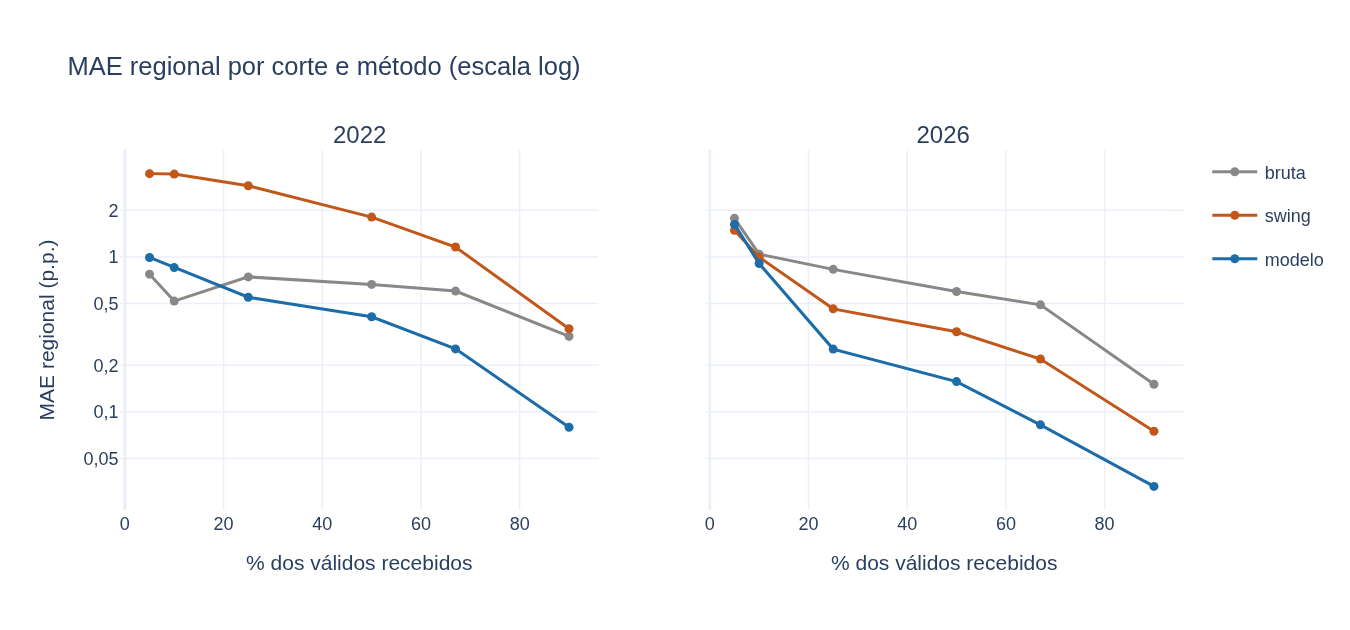

In [8]:
G.mostrar_e_salvar(G.erro_por_corte(TAB_ERROS, ANOS, "erro_brasil_pp", "erro absoluto do Brasil (p.p.)", "Erro do Brasil por corte e método (escala log)"), "apuracao_erro_brasil")
G.mostrar_e_salvar(G.erro_por_corte(TAB_ERROS, ANOS, "mae_regional_pp", "MAE regional (p.p.)", "MAE regional por corte e método (escala log)"), "apuracao_mae_regional")

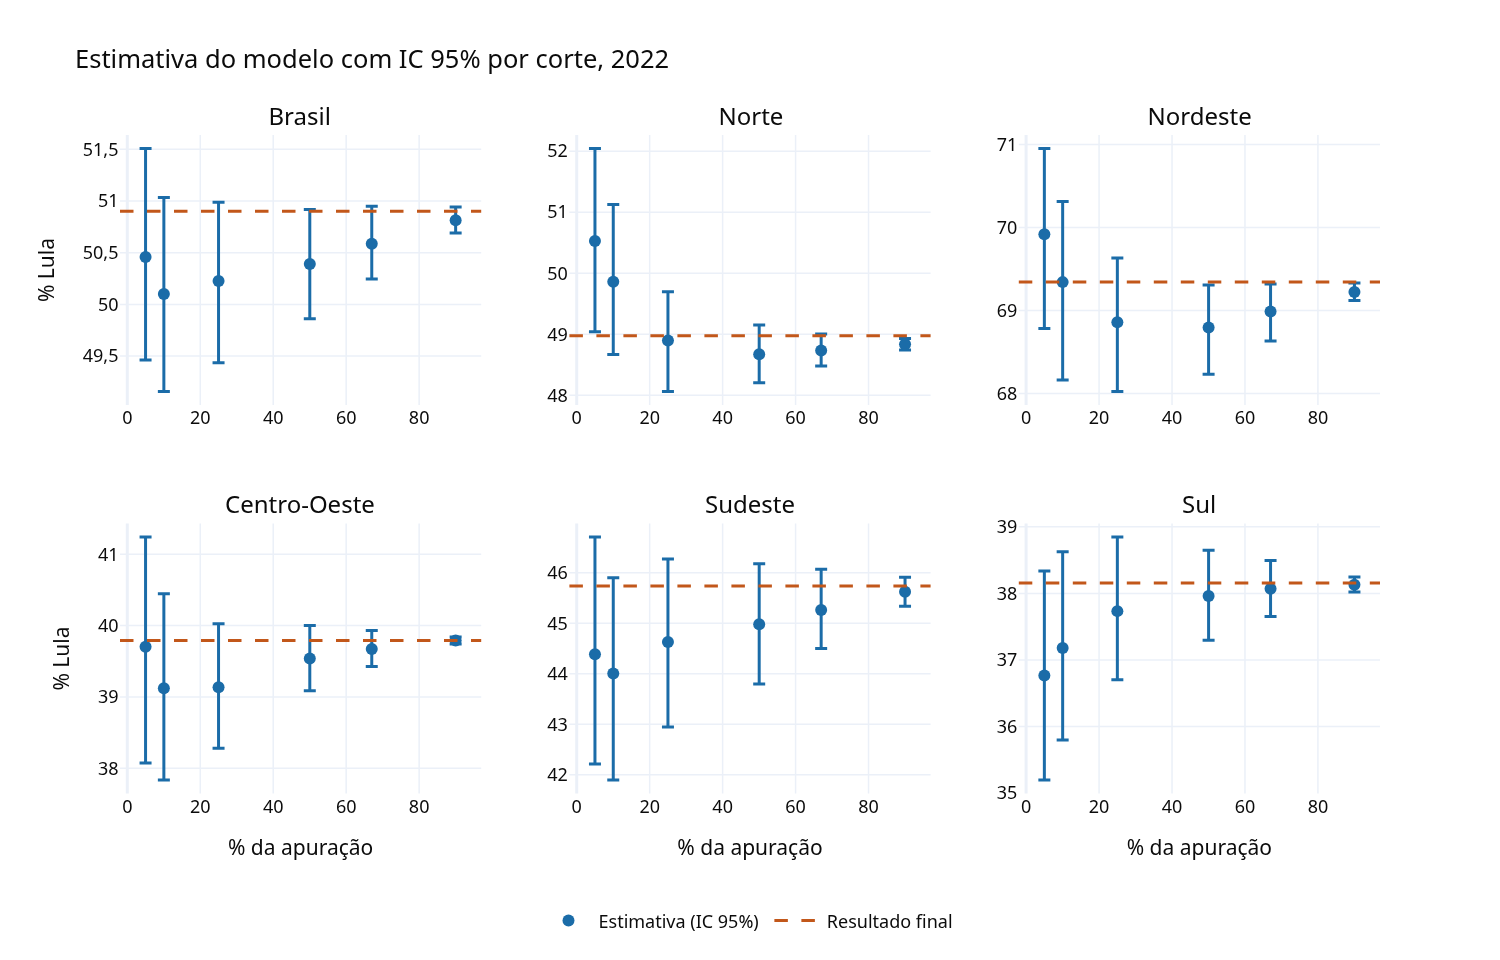

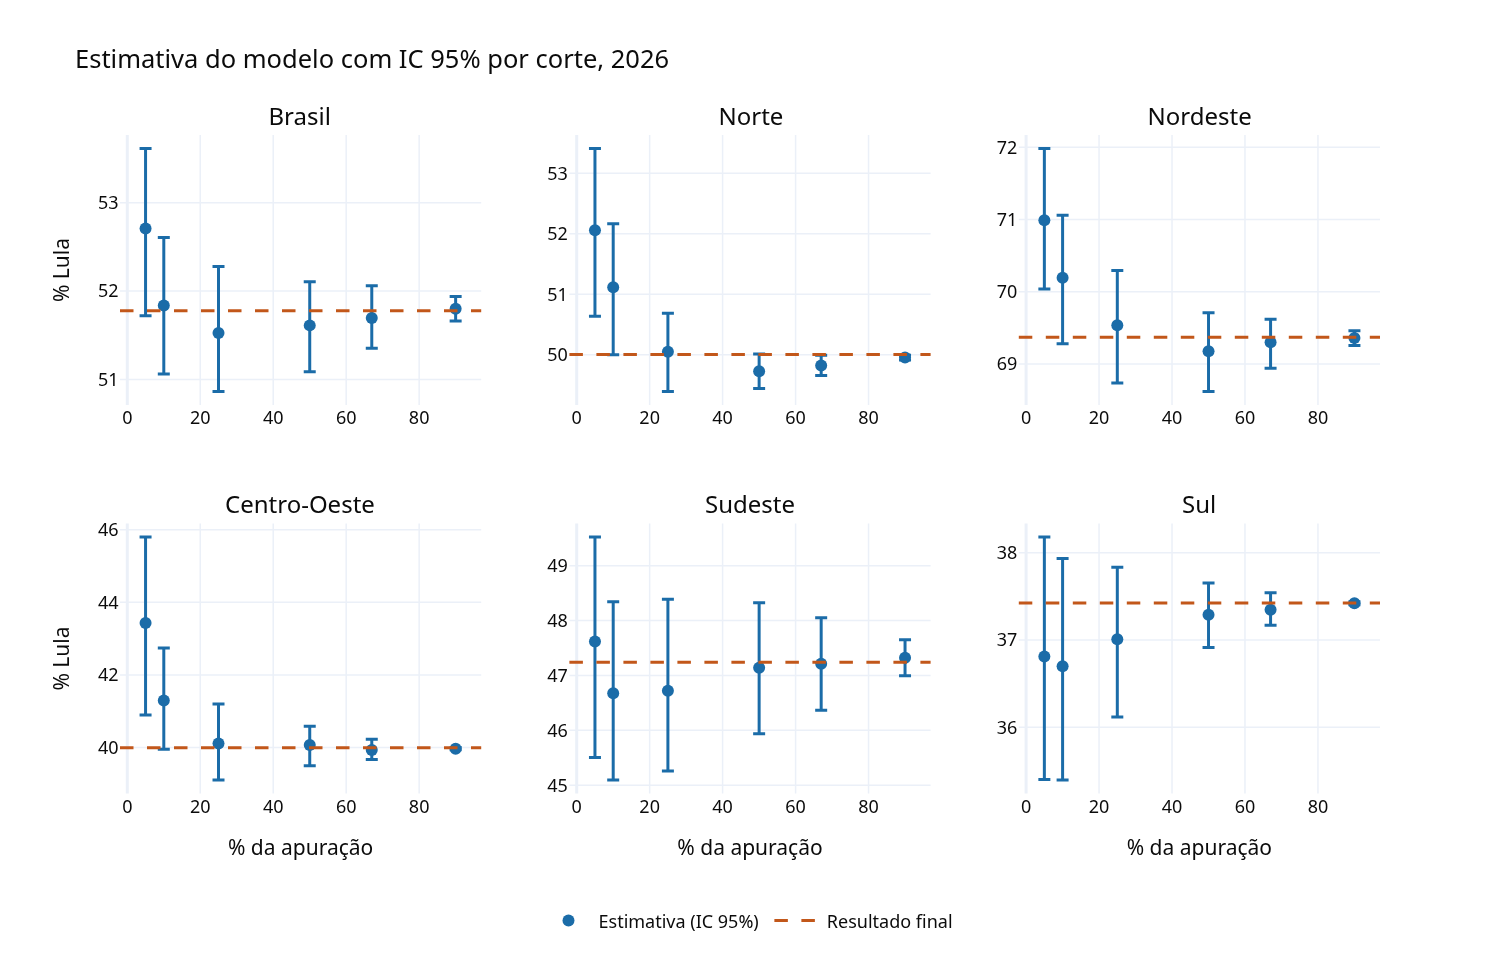

In [9]:
for ano in ANOS:
    G.mostrar_e_salvar(G.estimativa_por_corte(IC, f"Estimativa do modelo com IC 95% por corte, {ano}", ano=ano), f"apuracao_estimativa_corte_{ano}")

**Leitura.** Em 2022 o IC 95% do Brasil contém o resultado final (50,90%) nos 6 cortes e a largura cai de 2,05 p.p. aos 5% para 0,25 p.p. aos 90%. Em 2026 também contém o final (51,78%): a estimativa aos 5% é 52,71%, 0,93 p.p. acima, e de 10% em diante fica a no máximo 0,25 p.p. do resultado final. Nas regiões, o Nordeste em 2022 (3 de 6 cortes) e o Norte (4 em 2022, 3 em 2026) deixam o final fora do IC em vários cortes (tabela 5).

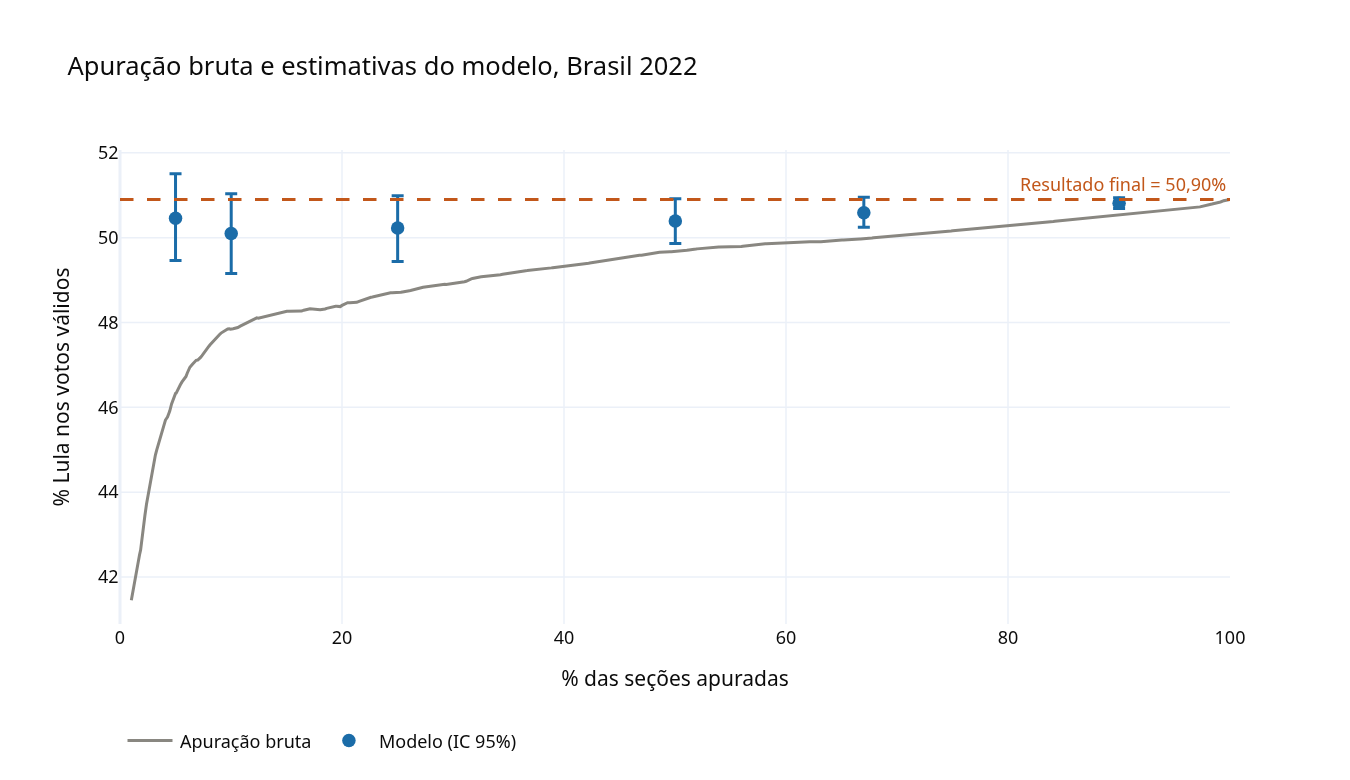

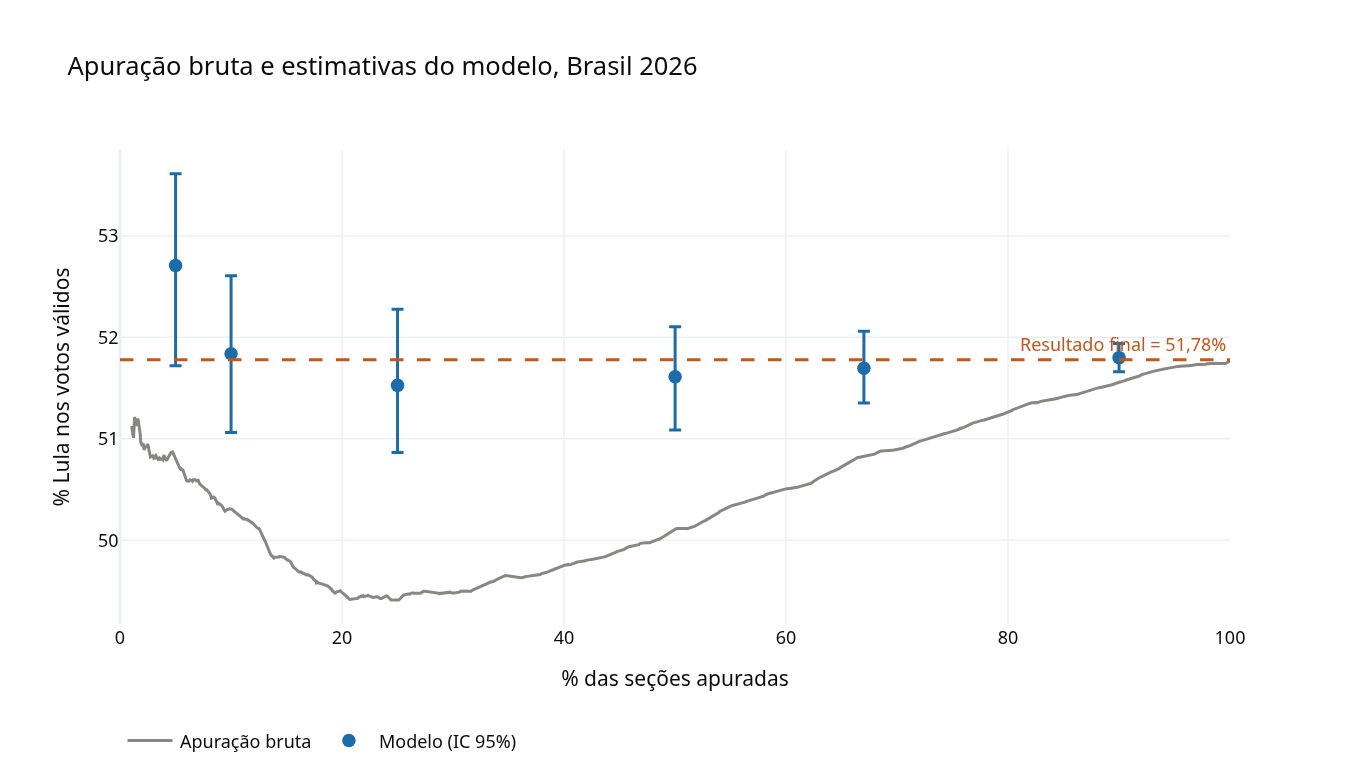

In [10]:
for ano in ANOS:
    curva = pd.read_csv(TAB / f"apuracao_curva_{ano}.csv")
    est = IC[(IC.ano == ano) & (IC.regiao == "Brasil")]
    G.mostrar_e_salvar(G.curva_apuracao(curva[curva.pct_recebido >= 1], est, float(est.real_pct.iloc[0]), f"Apuração bruta e estimativas do modelo, Brasil {ano}"), f"apuracao_curva_{ano}")

**Leitura.** Em 2022 a contagem bruta parte de 46,3% aos 5% apurados e só se aproxima do resultado final (50,90%) no fim; a virada de Lula sobre Bolsonaro ocorre em 68,1% (50,0%). As estimativas do modelo ficam entre 50,1% e 50,8% desde o primeiro corte. Em 2026 a bruta fica abaixo do final (51,78%), com 50,4% aos 56,6% apurados, e as estimativas do modelo ficam entre 51,5% e 52,7%. A diferença entre as duas é o que o modelo acrescenta: a ordem de chegada dos boletins não é aleatória.

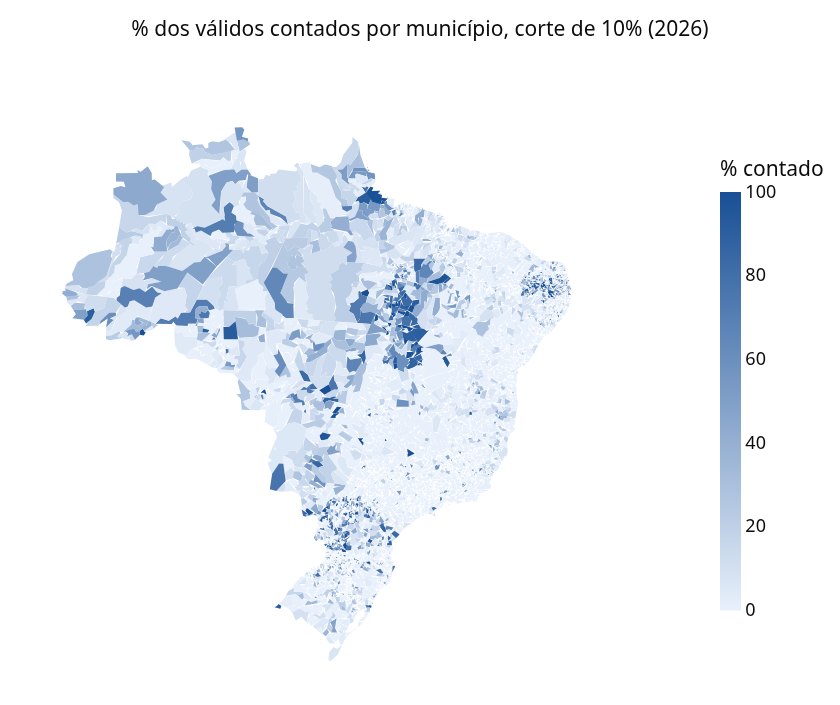

In [11]:
import geopandas as gpd
s26 = secoes[secoes.ano == 2026]
CORTE_MAPA = 10
rec = A.recebidas_ate(s26, CORTE_MAPA)
contado = s26[rec].groupby("cd_municipio_tse")["validos"].sum()
total_mun = s26.groupby("cd_municipio_tse")["validos"].sum()
pct_mun = (100 * contado / total_mun).reindex(cd_modelo).fillna(0.0)
geo_s = BD.gdf.copy(); geo_s["geometry"] = geo_s.geometry.simplify(0.12)
hov = (dfm["nome_municipio"].astype(str) + " (" + dfm["sigla_uf"].astype(str) + ")").tolist()
G.mapa(geo_s, pct_mun, f"% dos válidos contados por município, corte de {CORTE_MAPA}% (2026)", "apuracao_mapa_contado_2026", "% contado",
       escala=[[0, "#e8f0fb"], [1, "#184f95"]], zmin=0, zmax=100, hover=hov)

**Leitura.** Aos 10% do total nacional, em 2026, 62,1% dos municípios ainda não tinham nenhuma seção recebida e só 572 (10,3%) tinham metade ou mais dos votos válidos contados (183 já completos). Pesada por votos, a parcela contada é de 31,2% no Norte e 20,9% no Centro-Oeste, contra 2,8% no Sudeste e 8,3% no Nordeste. O modelo ajustado nesse corte vê, portanto, poucos municípios e uma amostra enviesada para as regiões que apuram primeiro; por isso o corte de 5% e 10% é o mais incerto.

## Pressuposto declarado: as seções apuradas representam as não apuradas?

Dentro de um município, o modelo supõe que o restante tem o mesmo share que o apurado, dado o que as covariáveis dizem do município. Isso falha onde a ordem de chegada se correlaciona com o voto dentro do município (capitais grandes: zonas centrais e periferias chegam em tempos diferentes). Medida: nos 20 maiores municípios (por válidos finais) e nos demais, a diferença entre o share apurado (ou o π̂ do modelo) e o share **real do restante**, média ponderada pelos votos restantes reais, só em municípios com apuração iniciada e restante > 0.

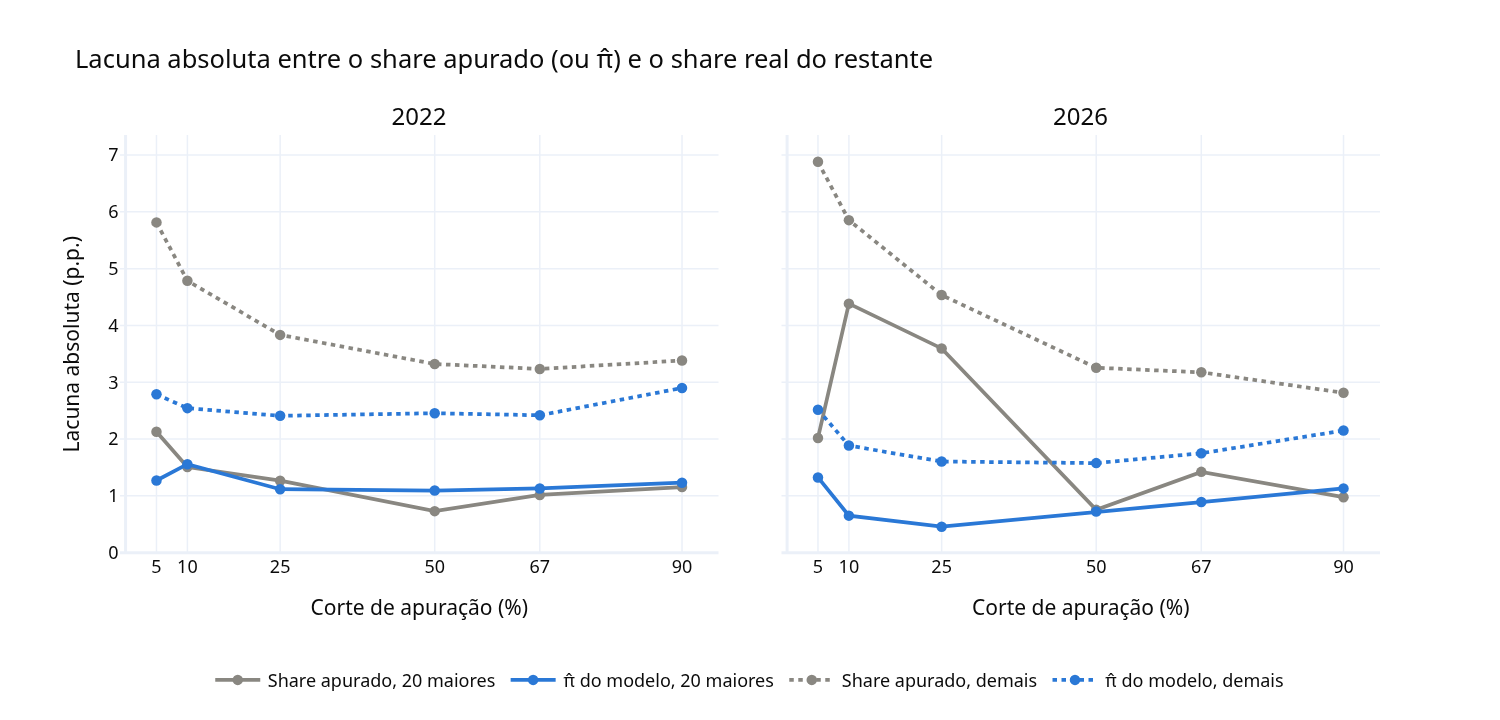

In [12]:
G.mostrar_e_salvar(G.representatividade_por_corte(REP, "Lacuna absoluta entre o share apurado (ou π̂) e o share real do restante"), "apuracao_representatividade")

## Leitura

**Veredito pela regra fixada de antemão (modelo menor que a contagem bruta e que o swing uniforme, no erro do Brasil e no MAE regional, em pelo menos 4 de 6 cortes): modelo útil nos dois anos.**

- **2022:** vitórias em 4 de 6 cortes (25, 50, 67 e 90%). Perde o MAE regional a 5% (0,99 contra 0,77 da bruta) e a 10% (0,85 contra 0,52). Erro do Brasil: 0,44 / 0,80 / 0,67 / 0,51 / 0,32 / 0,09 p.p. nos cortes 5 a 90, contra 4,57 a 0,38 da bruta e 0,13 a 1,62 do swing.
- **2026:** vitórias em 5 de 6 cortes. Só perde o MAE regional a 5% (1,62 contra 1,49 do swing). Erro do Brasil: 0,93 / 0,06 / 0,25 / 0,17 / 0,08 / 0,02 p.p., contra bruta de 0,22 a 2,37 e swing de 0,14 a 1,19.
- O modelo vence no erro do Brasil nos 12 cortes dos dois anos. A margem de 2022 sobre a regra é mínima (4 de 6): a conclusão de 2022 é frágil, a de 2026 é mais folgada.
- **Cobertura do IC 95% por unidade e ano** (cortes cobertos de 6, tabela 5, arquivo `apuracao_cobertura_unidade.csv`): o Brasil fica dentro em 6 de 6 nos dois anos; Nordeste 2022 (3) e Norte (4 em 2022, 3 em 2026) são as unidades mais abaixo do nominal. Simular a incerteza de n_u não mudou nenhuma contagem e alterou a largura em menos de 0,05 p.p. Os cortes são aninhados no tempo e as unidades são correlacionadas: a tabela é descritiva, não um teste de calibração. σ_UF de 2026 e corte de Conley foram reusados em 2022 (limitação).
- **Taxa de n_u:** a leitura literal (só os dois candidatos do 1º turno) erra 6,6% (2022) e 9,5% (2026) por município; a de todos os válidos erra 2,1% e 4,1% e foi a adotada. A escolha usou a comparação com o n final, e isso é declarado. Mesmo assim, n_u subestima o restante em 0,3% (2022) a 4,8% (2026).
- **Representatividade nas capitais:** os 20 maiores municípios concentram 24% a 46% do restante real. O share apurado erra o share do restante em 0,7 a 4,4 p.p. nesse grupo (2026 a 10%: apurado 3,6 p.p. abaixo do restante) e em 2,8 a 6,9 p.p. nos demais. O modelo reduz a lacuna nos dois grupos na maioria dos cortes, mas a hipótese de que as seções apuradas representam as restantes dentro do município só é corrigida em parte pelas covariáveis.